В цьому ноутбуці відбуваєтся тестування рандомних активів на рандомному проміжку часу. Метою є візуальна перевірка коректність роботи бектест алгоритму

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import random
import yaml

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# stocks

In [3]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,SOL,XRP,DOGE,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.081809,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.081867,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.078676,0.212025,1.111869,11.943166,0.175209,600.638428


In [4]:
sequence_length = 365 * 3

In [5]:
token_num = 10

random_token = random.sample(df_stocks.columns.tolist(), token_num)
random_token

['ADA', 'SOL', 'BTC', 'XMR', 'XLM', 'ETH', 'LINK', 'XRP', 'DOGE', 'DOT']

In [6]:
# strategy={"threshold_ma200_sell": 1.5, "threshold_bolinger_sell": 2.0, "threshold_rsi_sell": 70.0, "threshold_ppo_sell": 10.0}
strategy={}

01:24:24 - cmdstanpy - INFO - Chain [1] start processing
01:24:25 - cmdstanpy - INFO - Chain [1] done processing


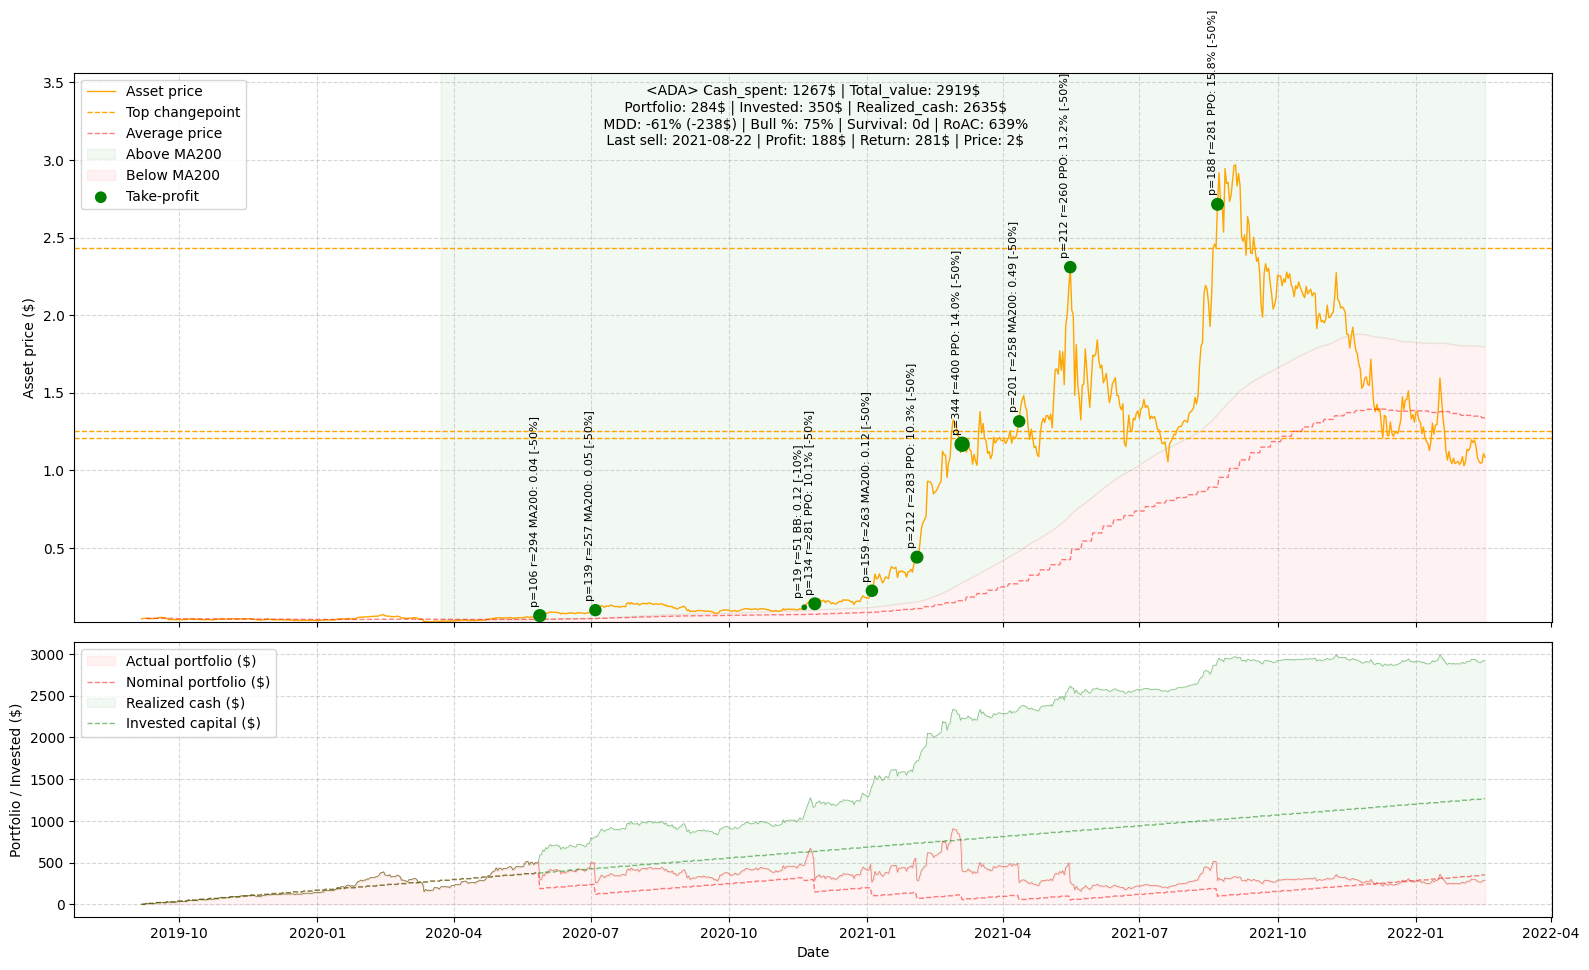

01:24:25 - cmdstanpy - INFO - Chain [1] start processing
01:24:25 - cmdstanpy - INFO - Chain [1] done processing


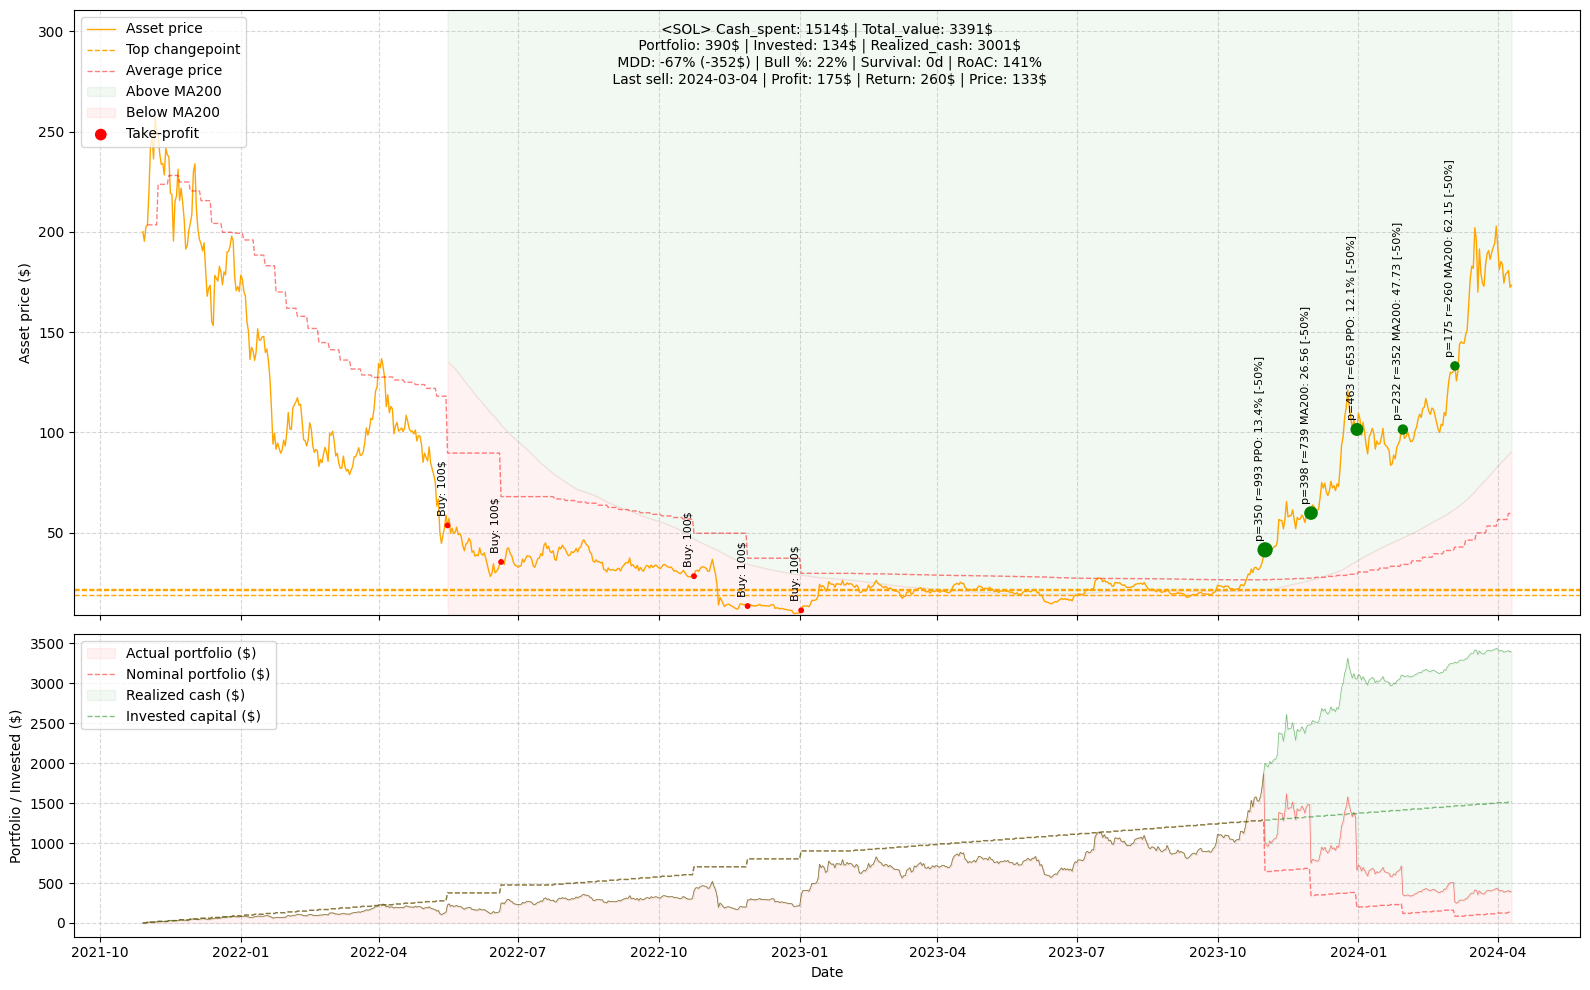

01:24:25 - cmdstanpy - INFO - Chain [1] start processing
01:24:26 - cmdstanpy - INFO - Chain [1] done processing


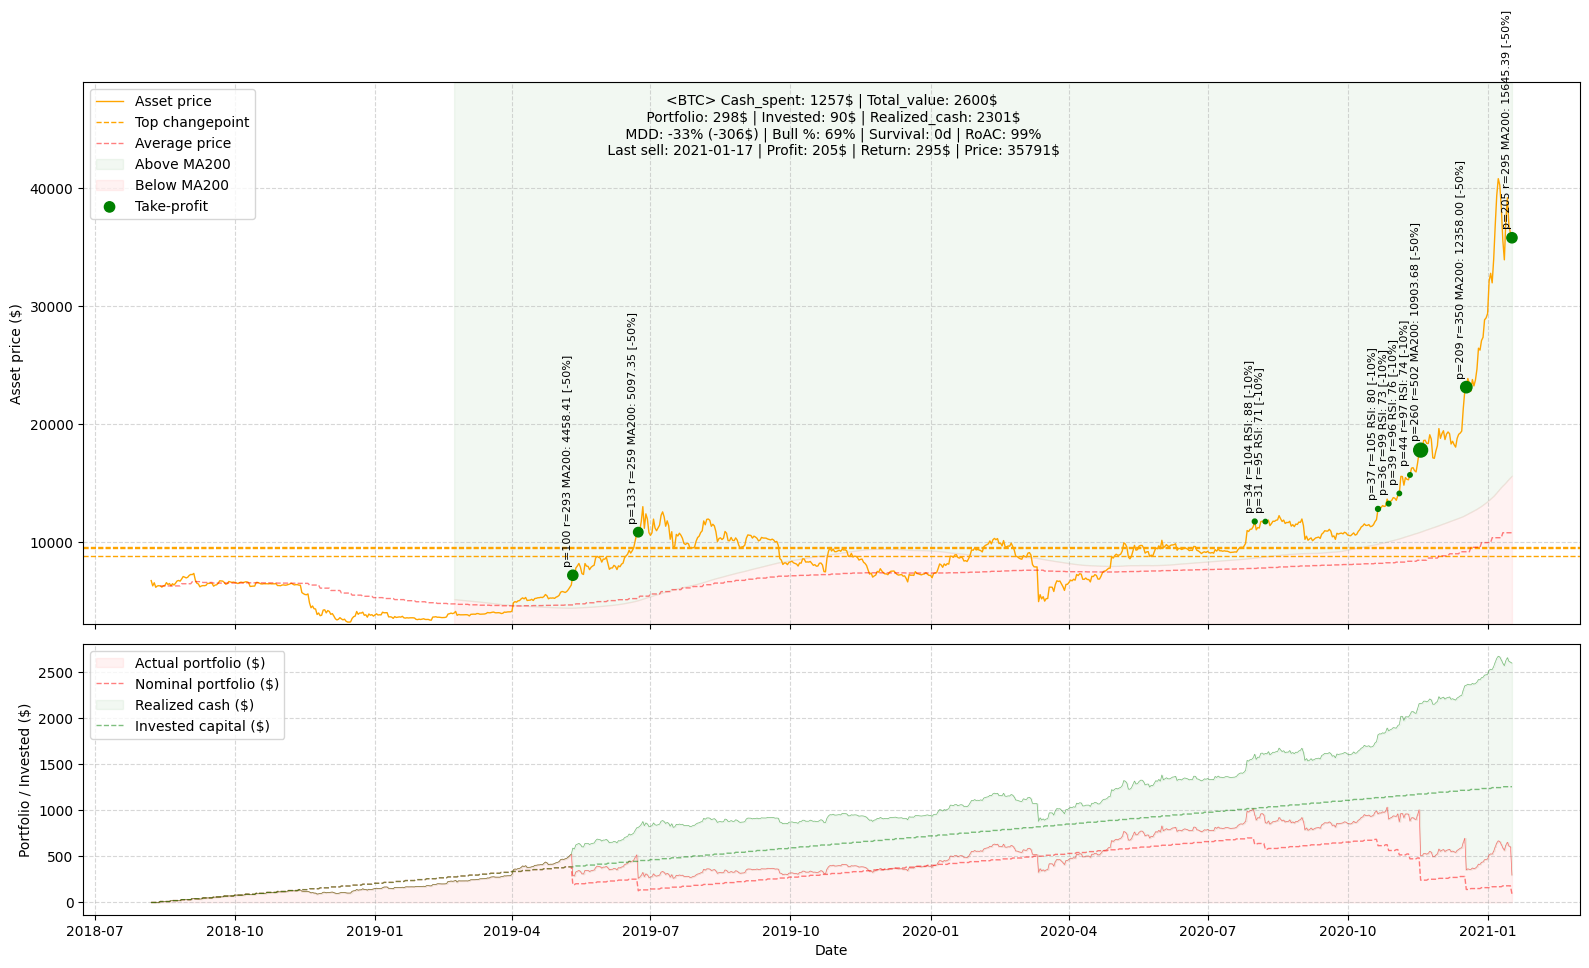

01:24:26 - cmdstanpy - INFO - Chain [1] start processing
01:24:26 - cmdstanpy - INFO - Chain [1] done processing


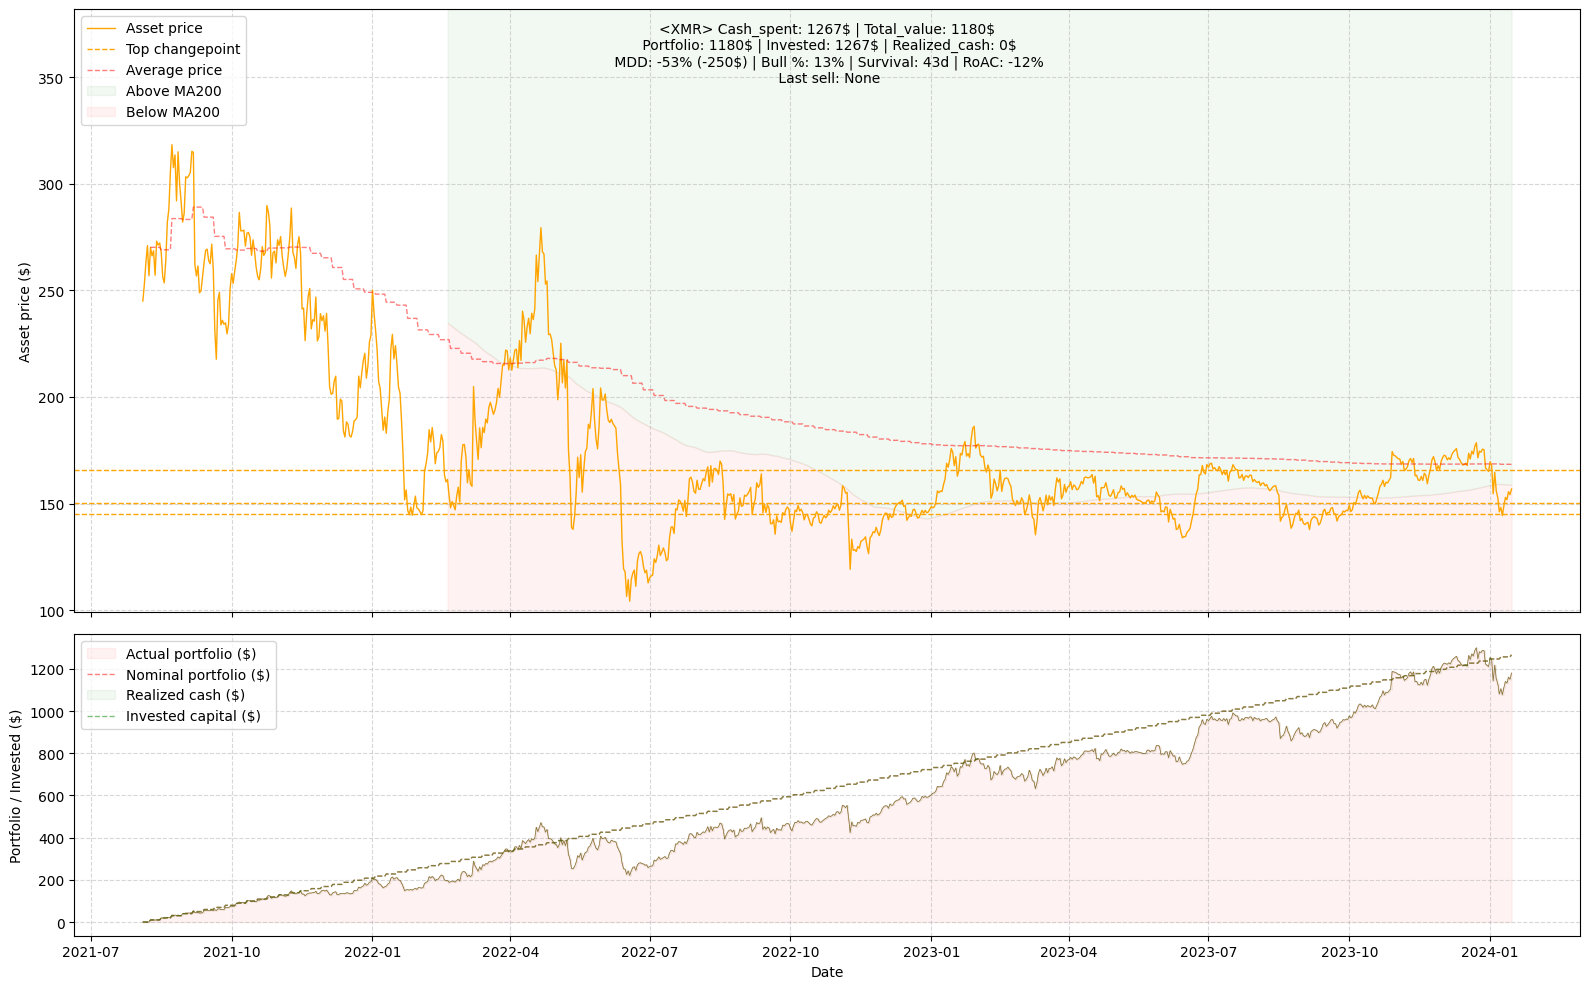

01:24:26 - cmdstanpy - INFO - Chain [1] start processing
01:24:26 - cmdstanpy - INFO - Chain [1] done processing


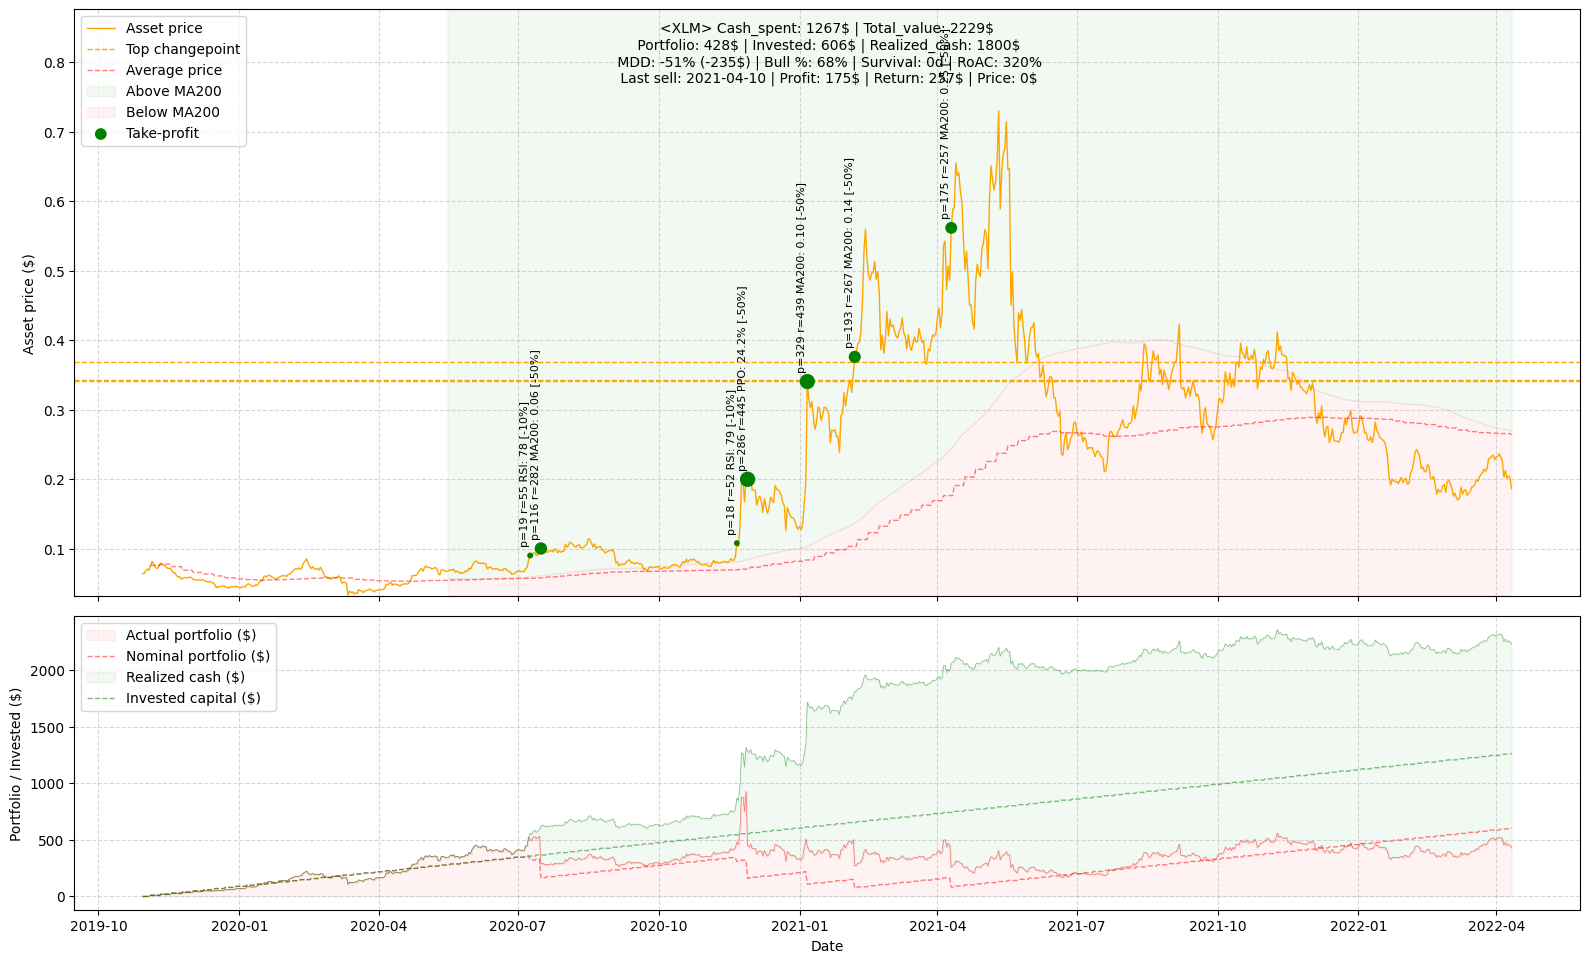

01:24:27 - cmdstanpy - INFO - Chain [1] start processing
01:24:27 - cmdstanpy - INFO - Chain [1] done processing


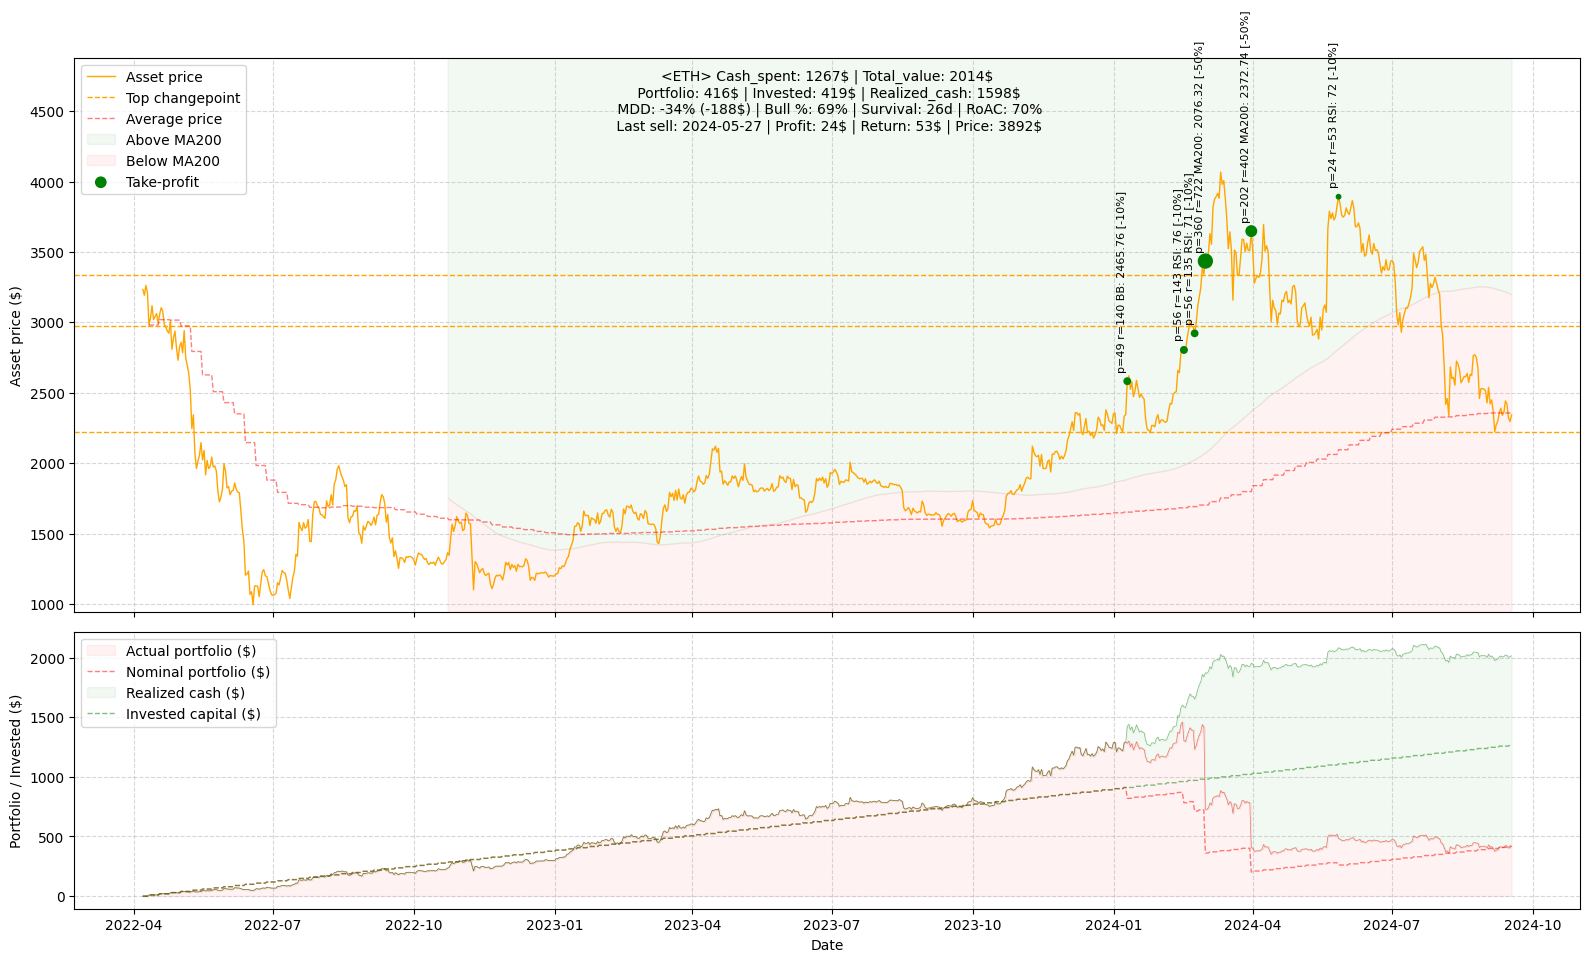

01:24:27 - cmdstanpy - INFO - Chain [1] start processing
01:24:27 - cmdstanpy - INFO - Chain [1] done processing


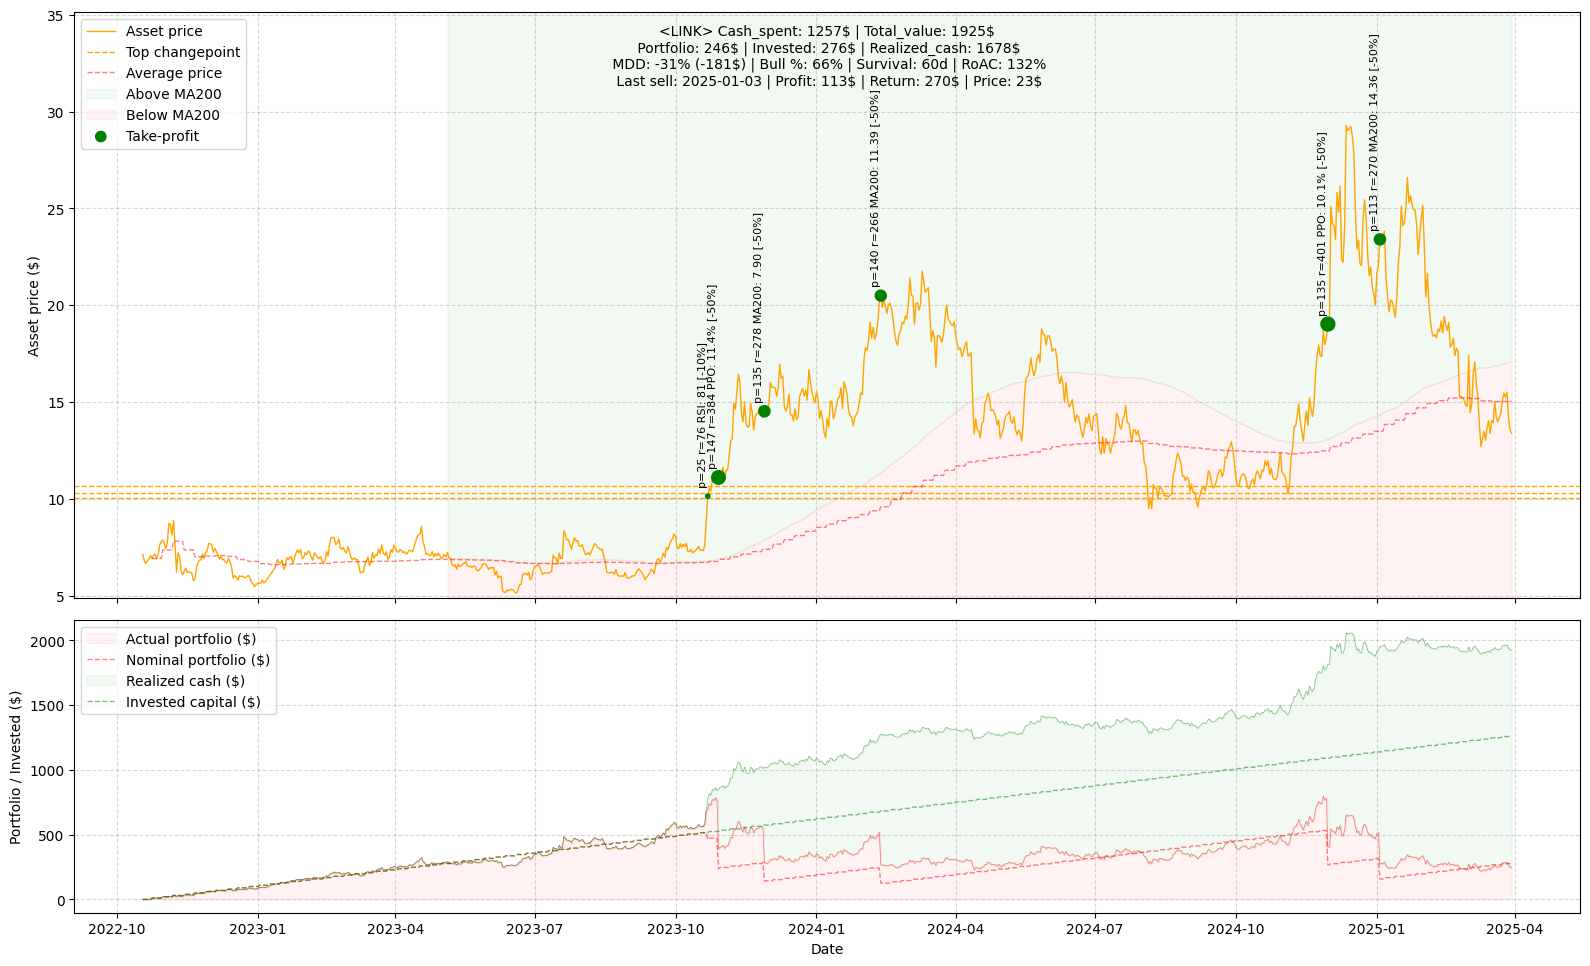

01:24:28 - cmdstanpy - INFO - Chain [1] start processing
01:24:28 - cmdstanpy - INFO - Chain [1] done processing


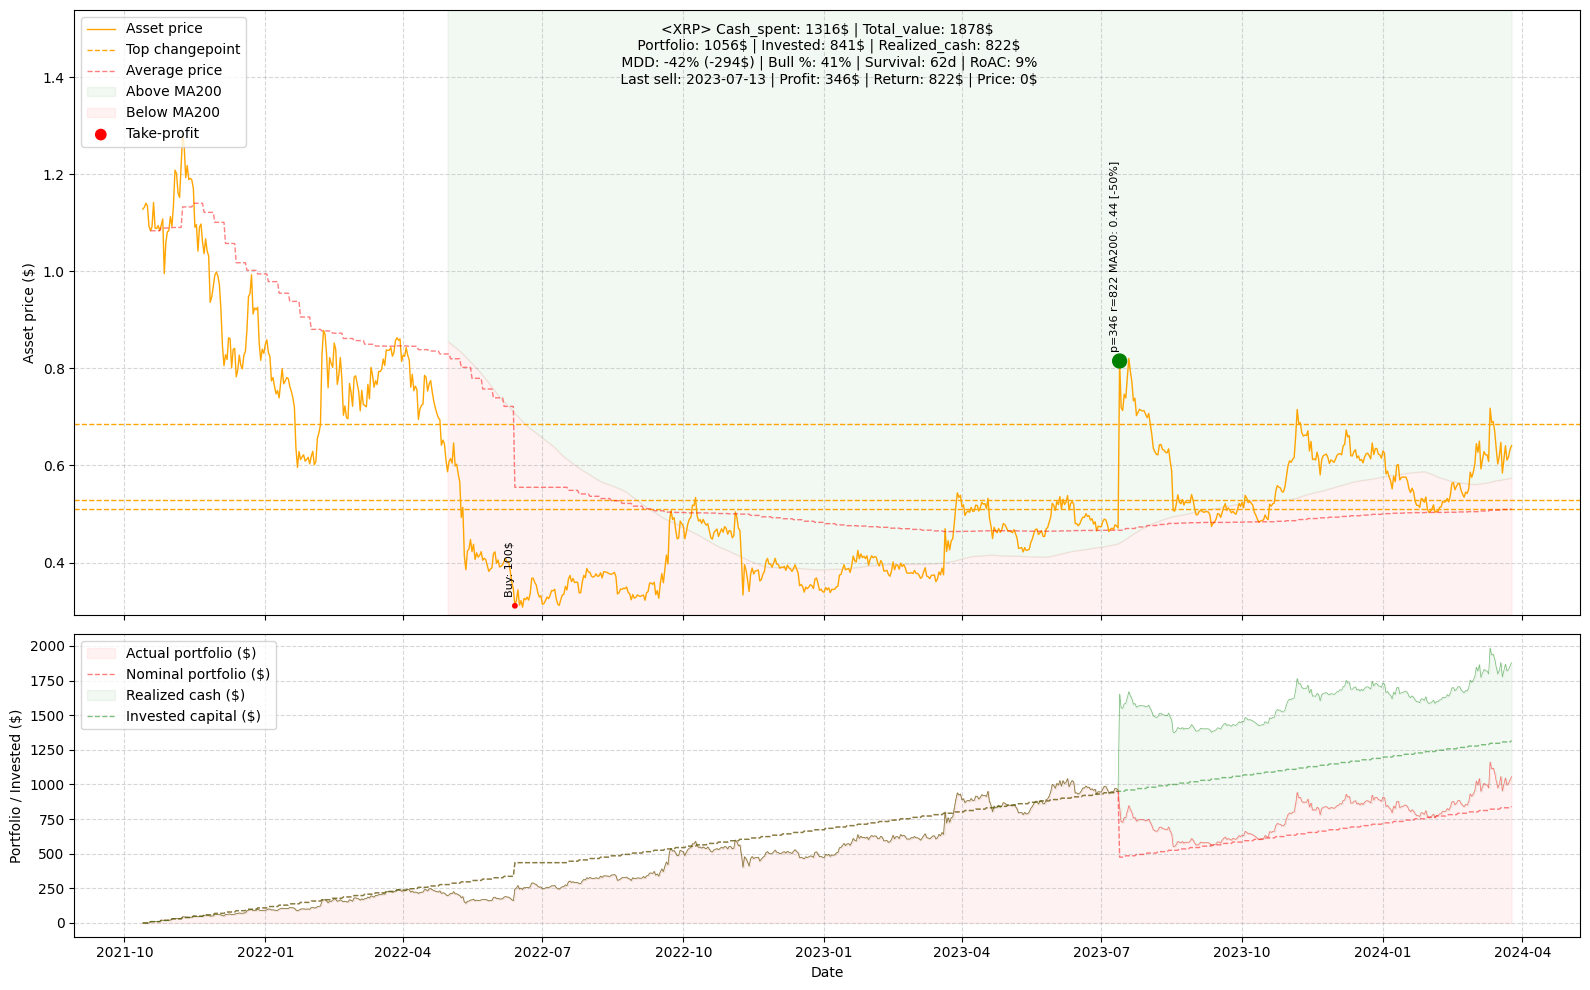

01:24:28 - cmdstanpy - INFO - Chain [1] start processing
01:24:28 - cmdstanpy - INFO - Chain [1] done processing


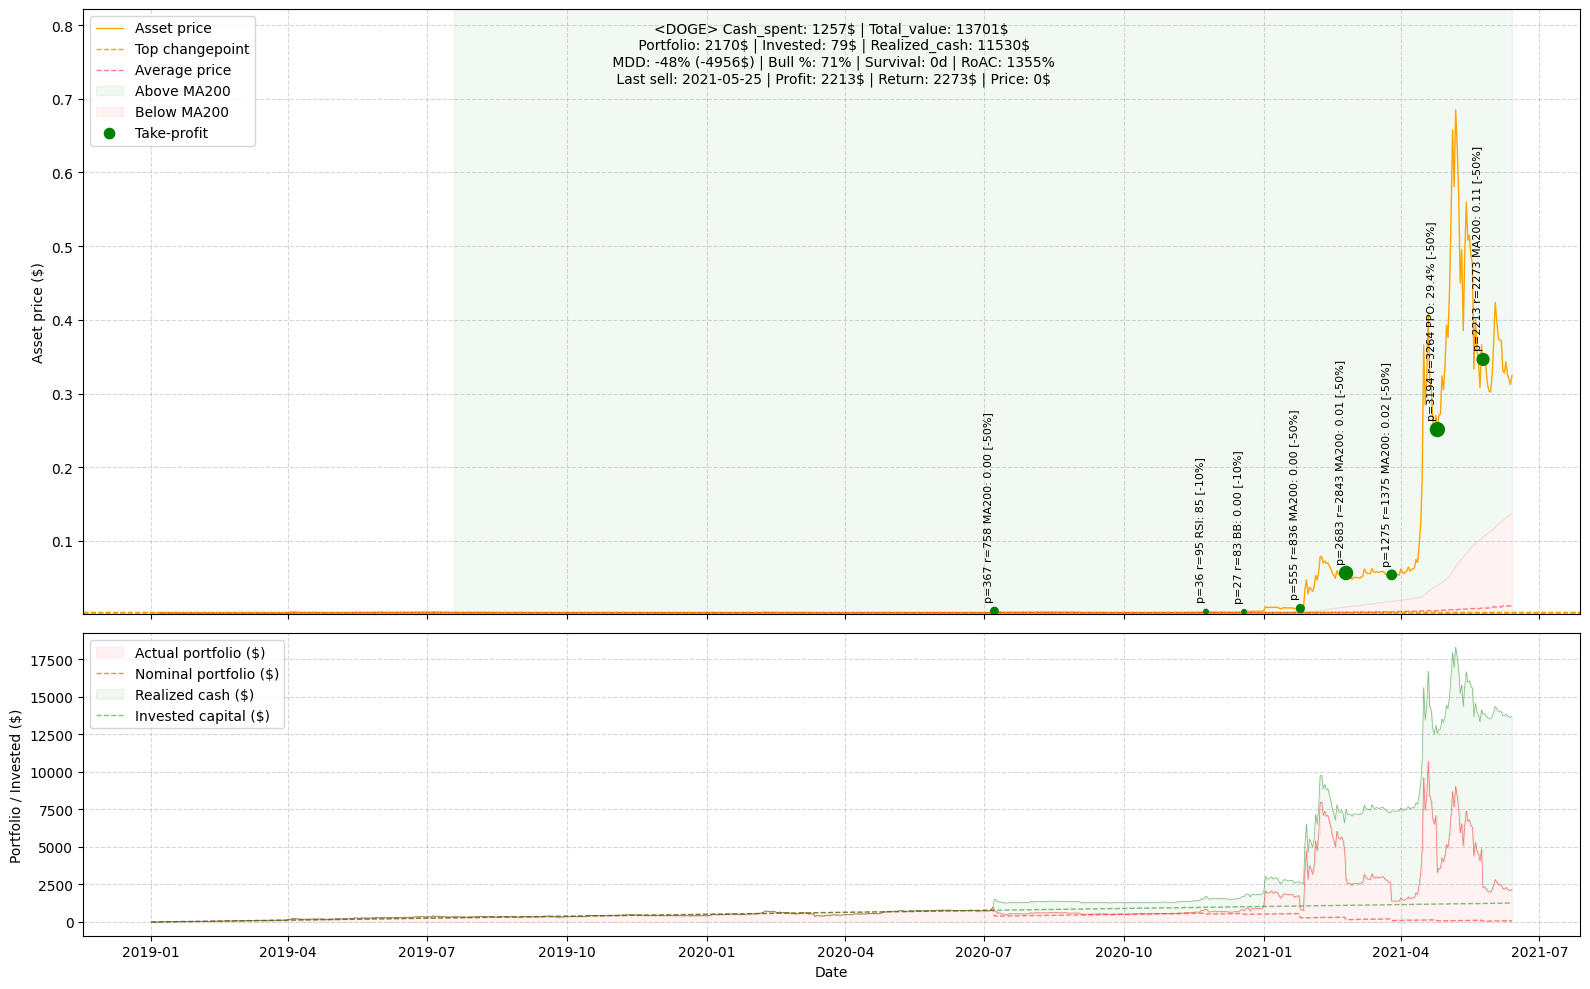

01:24:28 - cmdstanpy - INFO - Chain [1] start processing
01:24:29 - cmdstanpy - INFO - Chain [1] done processing


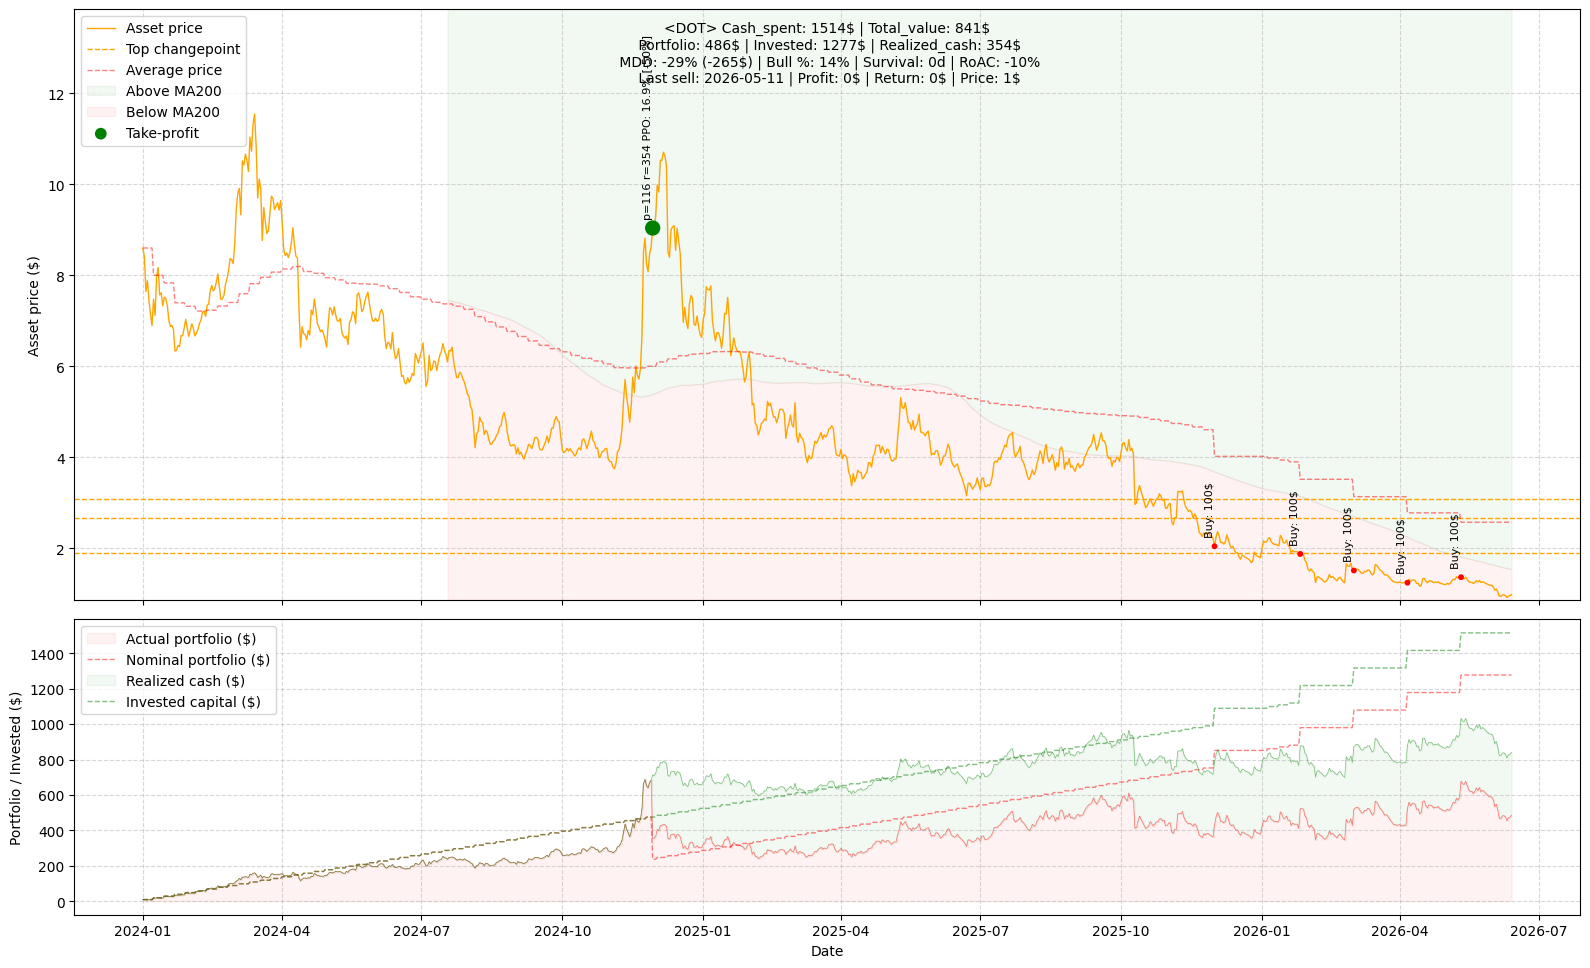

Total invested: $13183.00
Total return: $25719.00
Total value: $32678.00


In [7]:
total_invested = 0
total_profit = 0
total_return = 0
total_value = 0

for stock in random_token:

    prices = df_stocks[stock]
    prices = prices.dropna()
    start = random.randint(0, len(prices) - sequence_length)
    prices = prices.iloc[start:start + sequence_length]
    prices = prices.iloc[200:]

    try:
        bt = BacktestDCA(
        target=stock,
        prices=prices,
        strategy=strategy
        )
        result, metrics = bt.run()
        ploter(metrics=metrics, history=result)
    except Exception as e:
        print(f"Error backtesting {stock}: {e}")
        continue

    total_invested += metrics['Cash_spent']
    total_return += metrics['Realized_cash']
    total_value += metrics['Total_value']

print(f"Total invested: ${total_invested:.2f}")
print(f"Total return: ${total_return:.2f}")
print(f"Total value: ${total_value:.2f}")

In [8]:
result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2024-01-01,8.598925,1.151307,9.9,9.9,0.0,0.0,0.000000,,9.900000,8.598925,9.900000
2024-01-02,8.412696,1.151307,9.9,9.9,0.0,0.0,0.000000,,9.685594,8.598925,9.685594
2024-01-03,7.641823,1.151307,9.9,9.9,0.0,0.0,0.000000,,8.798082,8.598925,8.798082
2024-01-04,7.881476,1.151307,9.9,9.9,0.0,0.0,0.000000,,9.073996,8.598925,9.073996
2024-01-05,7.445562,1.151307,9.9,9.9,0.0,0.0,0.000000,,8.572126,8.598925,8.572126
...,...,...,...,...,...,...,...,...,...,...,...
2026-06-09,0.957792,496.761275,1277.1,1514.7,0.0,0.0,354.471105,,475.793967,2.570853,830.265072
2026-06-10,0.915945,496.761275,1277.1,1514.7,0.0,0.0,354.471105,,455.006003,2.570853,809.477108
2026-06-11,0.950443,496.761275,1277.1,1514.7,0.0,0.0,354.471105,,472.143291,2.570853,826.614396


In [9]:
(result['Portfolio'] > 0).sum()

np.int64(895)

In [10]:
metrics

{'Target': 'DOT',
 'Cash_spent': 1514,
 'Realized_cash': 354,
 'Portfolio': 486,
 'Invested': 1277,
 'Total_value': 841,
 'Bull_history': 14,
 'Avg_price': np.float64(2.570852570611404),
 'Num_take_profits': 6,
 'MDD': -29,
 'MDD_usd': -265,
 'MA200_survival_days': 0.0,
 'RoAC': -10}